# Smart Plant Growth Monitoring and Prediction System
## Data Visualization (DV)

This notebook creates five charts from `cleaned_plant_growth.csv`. Keep this notebook in the same folder as the cleaned CSV file.

Charts:
1. New Growth Count distribution (histogram)
2. Soil Moisture vs. New Growth (scatter plot)
3. Plant Height vs. New Growth (scatter plot)
4. Average New Growth by Soil Type (bar chart)
5. Average New Growth by Fertilizer Type (bar chart)

These are exploratory charts; they show patterns, not proof of cause and effect.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_plant_growth.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (1000, 29)


,Plant_ID,Height_cm,Leaf_Count,New_Growth_Count,Health_Notes,Watering_Amount_ml,Watering_Frequency_days,Sunlight_Exposure,Room_Temperature_C,Humidity_%,...,Soil_Type_Silty,Fertilizer_Type_Chemical,Fertilizer_Type_Compost,Fertilizer_Type_Liquid feed,Fertilizer_Type_No fertilizer,Fertilizer_Type_Organic,Pest_Severity_High,Pest_Severity_Low,Pest_Severity_Moderate,Pest_Severity_None
0,Sansevieria cylindrica,17.39,17,8,Yellowing leaves,205,3,3h direct morning sun,21.7,77.5,...,False,False,False,False,False,True,False,False,True,False
1,Aloe vera,9.84,31,9,No notes,191,1,3h direct morning sun,22.6,68.9,...,False,False,False,False,True,False,False,True,False,False
2,Ficus lyrata,19.82,40,8,Brittle leaves,477,5,Indirect light all day,17.2,44.3,...,False,False,False,True,False,False,True,False,False,False
3,Monstera deliciosa,37.08,11,1,New bud,207,1,Low light corner,25.0,72.2,...,False,False,True,False,False,False,False,True,False,False
4,Ficus lyrata,2.96,26,3,Wilting,465,2,Filtered sunlight through curtain,23.2,51.6,...,False,False,True,False,False,False,False,True,False,False


## 1. Histogram — Distribution of New Growth Count

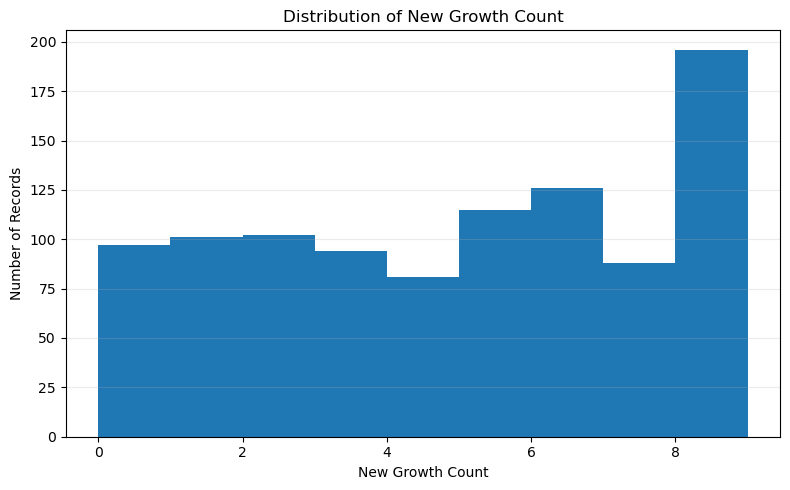

In [2]:
plt.figure(figsize=(8, 5))
plt.hist(df["New_Growth_Count"].dropna(), bins="auto")
plt.title("Distribution of New Growth Count")
plt.xlabel("New Growth Count")
plt.ylabel("Number of Records")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 2. Scatter Plot — Soil Moisture vs. New Growth

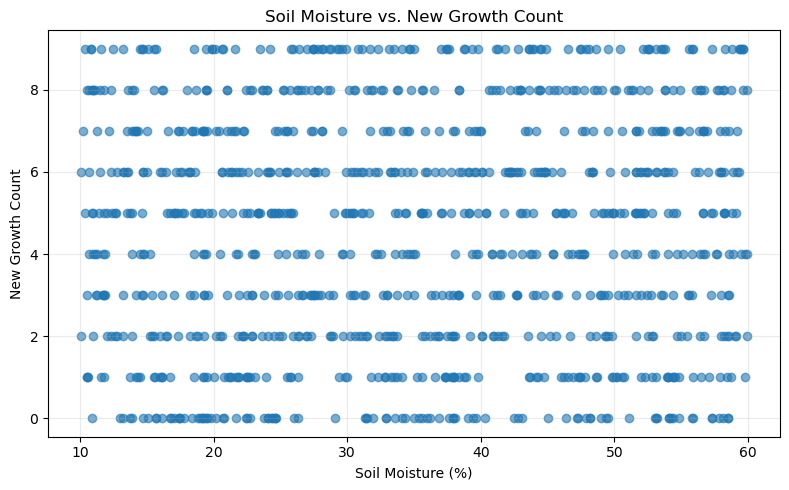

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Soil_Moisture_%"], df["New_Growth_Count"], alpha=0.6)
plt.title("Soil Moisture vs. New Growth Count")
plt.xlabel("Soil Moisture (%)")
plt.ylabel("New Growth Count")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Scatter Plot — Plant Height vs. New Growth

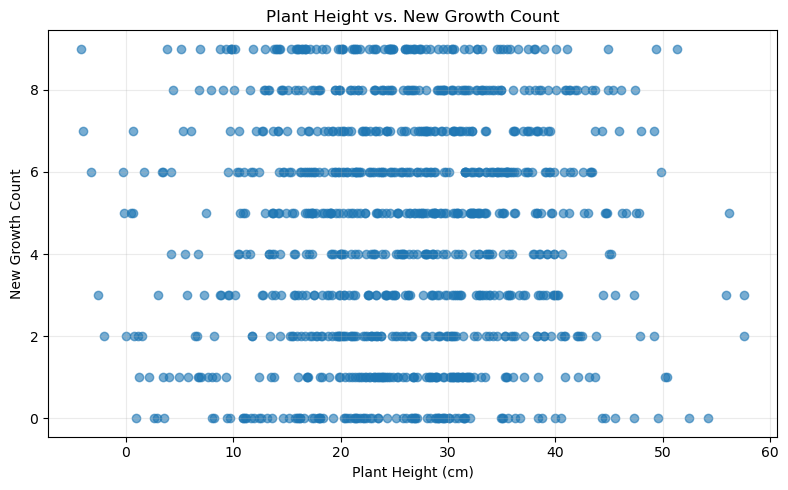

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Height_cm"], df["New_Growth_Count"], alpha=0.6)
plt.title("Plant Height vs. New Growth Count")
plt.xlabel("Plant Height (cm)")
plt.ylabel("New Growth Count")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Bar Chart — Average New Growth by Soil Type

The cleaned dataset has one-hot encoded `Soil_Type_...` columns. This cell uses those columns to identify each record's soil category.

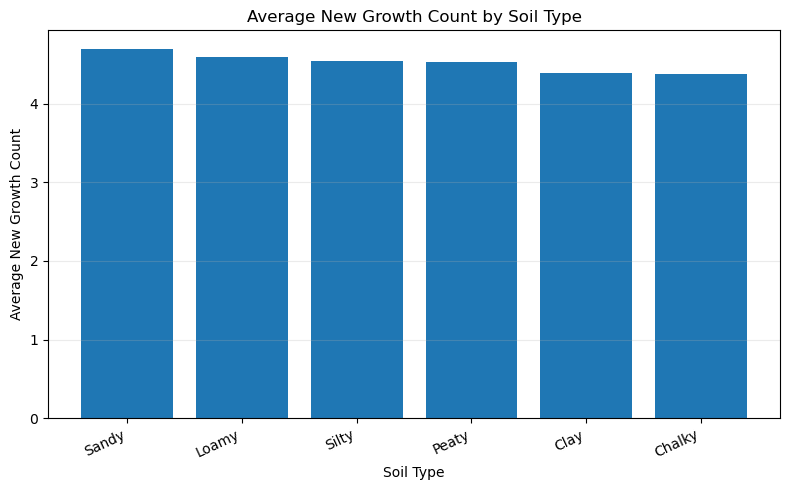

,Average New Growth Count
Soil_Type_Display,
Sandy,4.698113
Loamy,4.590361
Silty,4.547059
Peaty,4.531250
Clay,4.387283
Chalky,4.383721


In [5]:
soil_cols = [c for c in df.columns if c.startswith("Soil_Type_")]

if soil_cols:
    df["Soil_Type_Display"] = (
        df[soil_cols].fillna(0).idxmax(axis=1)
        .str.replace("Soil_Type_", "", regex=False)
    )
    soil_summary = df.groupby("Soil_Type_Display")["New_Growth_Count"].mean().sort_values(ascending=False)

    plt.figure(figsize=(8, 5))
    plt.bar(soil_summary.index, soil_summary.values)
    plt.title("Average New Growth Count by Soil Type")
    plt.xlabel("Soil Type")
    plt.ylabel("Average New Growth Count")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    display(soil_summary.to_frame("Average New Growth Count"))
else:
    print("No one-hot encoded Soil_Type columns were found.")

## 5. Bar Chart — Average New Growth by Fertilizer Type

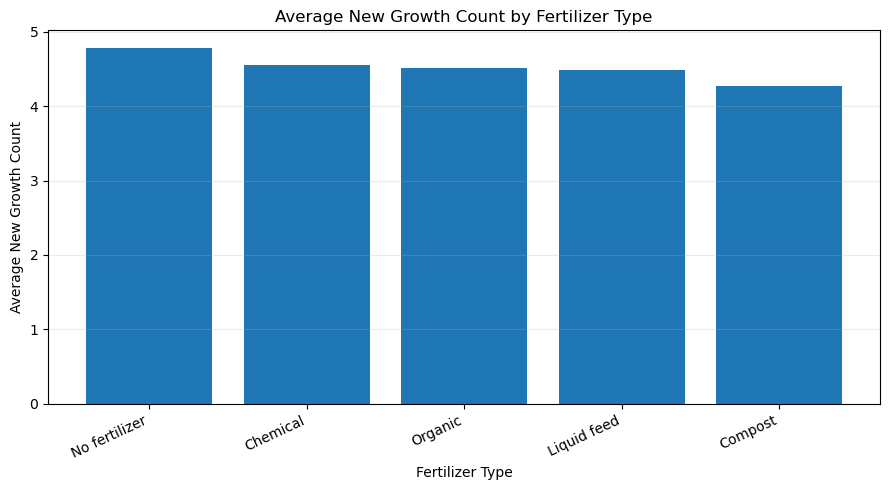

,Average New Growth Count
Fertilizer_Type_Display,
No fertilizer,4.779487
Chemical,4.546296
Organic,4.518325
Liquid feed,4.490099
Compost,4.265306


In [6]:
fertilizer_cols = [c for c in df.columns if c.startswith("Fertilizer_Type_")]

if fertilizer_cols:
    df["Fertilizer_Type_Display"] = (
        df[fertilizer_cols].fillna(0).idxmax(axis=1)
        .str.replace("Fertilizer_Type_", "", regex=False)
    )
    fertilizer_summary = df.groupby("Fertilizer_Type_Display")["New_Growth_Count"].mean().sort_values(ascending=False)

    plt.figure(figsize=(9, 5))
    plt.bar(fertilizer_summary.index, fertilizer_summary.values)
    plt.title("Average New Growth Count by Fertilizer Type")
    plt.xlabel("Fertilizer Type")
    plt.ylabel("Average New Growth Count")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    display(fertilizer_summary.to_frame("Average New Growth Count"))
else:
    print("No one-hot encoded Fertilizer_Type columns were found.")

## Interpretation Notes

- The histogram shows the distribution of new growth counts.
- Scatter plots help explore relationships between soil moisture, plant height, and new growth.
- Bar charts compare average new growth across soil and fertilizer categories.
- These charts do not prove that a factor causes plant growth.
- Keep `cleaned_plant_growth.csv` in the same folder as this notebook.